# 03. Statistical Hypothesis Testing: Austin Airbnb Market

**Project:** Airbnb Market Analysis: Pricing Drivers and Guest Sentiment for Austin, TX  
**Dataset Snapshot:** September 17, 2026 (Inside Airbnb)  
**Objective:** Move beyond descriptive statistics to formal inferential testing. Test 4 core hypotheses regarding pricing premiums, room type variance, Superhost rating superiority, and price-to-satisfaction independence.

---
### Rigorous Hypothesis Testing Framework
For every hypothesis, we adhere to the standard scientific methodology:
1. **Hypothesis Formulation**: Formal Null ($H_0$) and Alternative ($H_1$) hypotheses.
2. **Assumption Diagnostics**: Checking normality (D'Agostino-Pearson / Shapiro-Wilk) and equal variance (Levene's test).
3. **Statistical Test Execution**: Running both parametric (Welch's t-test, ANOVA) and non-parametric tests (Mann-Whitney U, Kruskal-Wallis, Spearman rho).
4. **Effect Size Quantification**: Reporting Cohen's $d$, Eta-squared ($\eta^2$), Cliff's Delta, and Fisher $z$ confidence intervals.
5. **Business Interpretation**: Plain-English decision-making implications.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath(".."))
from src.statistical_tests import (
    check_normality_and_variance, compute_cohens_d, compute_cliffs_delta,
    test_superhost_price, test_room_type_price, test_superhost_ratings,
    test_price_rating_correlation
)

# Plotting configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
df = pd.read_csv("../data/processed/listings_cleaned.csv")
print(f"Loaded {len(df):,} listings for statistical testing.")


Loaded 9,945 listings for statistical testing.


## 1. Hypothesis A: Superhost Pricing Premium

- **Research Question**: Do Superhosts charge significantly higher nightly rates than regular hosts?
- **Null Hypothesis ($H_0$)**: $\mu_{	ext{superhost}} = \mu_{	ext{regular}}$ (Zero price difference).
- **Alternative Hypothesis ($H_1$)**: $\mu_{	ext{superhost}} > \mu_{	ext{regular}}$ (Superhosts charge a premium).


In [2]:
res_a = test_superhost_price(df)

print(f"Superhost Sample Mean: ${res_a['superhost_mean_price']:,.2f} (Median: ${res_a['superhost_median_price']:,.2f})")
print(f"Regular Host Sample Mean: ${res_a['regular_mean_price']:,.2f} (Median: ${res_a['regular_median_price']:,.2f})")
print(f"Welch's Two-Sample t-test: t = {res_a['welch_t_stat']}, p = {res_a['welch_p_value']:.2e}")
print(f"Cohen's d Effect Size: {res_a['cohens_d']} (Small positive effect)")
print(f"Mann-Whitney U Test: U = {res_a['mann_whitney_u']:,.0f}, p = {res_a['mann_whitney_p']:.2e}, Rank-Biserial r = {res_a['rank_biserial_r']}")


Superhost Sample Mean: $347.78 (Median: $248.50)
Regular Host Sample Mean: $305.21 (Median: $211.89)
Welch's Two-Sample t-test: t = 11.5666, p = 9.65e-31
Cohen's d Effect Size: 0.2326 (Small positive effect)
Mann-Whitney U Test: U = 14,040,661, p = 4.05e-32, Rank-Biserial r = -0.1367


> **Statistical Decision**: **Reject $H_0$** ($p = 9.65 	imes 10^{-31} < 0.001$).
>
> 📌 **Plain-English Interpretation**: Superhosts charge statistically significantly more than regular hosts (median $248.50 vs $211.89, +$36.61/night). The Cohen's $d$ of **0.23** confirms a reliable, small-to-moderate positive effect size. Superhost status grants verified pricing power.


## 2. Hypothesis B: Price Differences Across Room Privacy Tiers

- **Research Question**: Does nightly price differ significantly across the 4 room types?
- **Null Hypothesis ($H_0$)**: $\mu_{	ext{Entire}} = \mu_{	ext{Private}} = \mu_{	ext{Hotel}} = \mu_{	ext{Shared}}$
- **Alternative Hypothesis ($H_1$)**: At least one room type's mean price differs from the others.


In [3]:
res_b, tukey = test_room_type_price(df)

print(f"One-Way ANOVA on log(price): F = {res_b['anova_f_stat']}, p = {res_b['anova_p_value']:.2e}")
print(f"Eta-Squared (Effect Size): eta^2 = {res_b['eta_squared']} (Large effect: 13.8% variance explained)")
print(f"Kruskal-Wallis Rank-Sum Test: H = {res_b['kruskal_wallis_h']}, p = {res_b['kruskal_p_value']:.2e}")
print("\nPost-Hoc Pairwise Comparisons (Tukey HSD at FWER=0.05):")
print(tukey.summary())


One-Way ANOVA on log(price): F = 530.0723, p = 1.40e-319
Eta-Squared (Effect Size): eta^2 = 0.1379 (Large effect: 13.8% variance explained)
Kruskal-Wallis Rank-Sum Test: H = 1008.7936, p = 2.23e-218

Post-Hoc Pairwise Comparisons (Tukey HSD at FWER=0.05):
       Multiple Comparison of Means - Tukey HSD, FWER=0.05        
     group1        group2    meandiff p-adj  lower   upper  reject
------------------------------------------------------------------
Entire home/apt   Hotel room   0.3308   0.0  0.1779  0.4837   True
Entire home/apt Private room  -0.7927   0.0 -0.8474  -0.738   True
Entire home/apt  Shared room  -2.0266   0.0 -2.4331 -1.6201   True
     Hotel room Private room  -1.1235   0.0 -1.2833 -0.9638   True
     Hotel room  Shared room  -2.3574   0.0 -2.7907 -1.9241   True
   Private room  Shared room  -1.2339   0.0  -1.643 -0.8247   True
------------------------------------------------------------------


> **Statistical Decision**: **Reject $H_0$** ($F = 530.07, p < 0.001, \eta^2 = 0.138$).
>
> 📌 **Plain-English Interpretation**: Room type is a primary driver of pricing variance in Austin, explaining **13.8% of all variance in log-price**. Tukey's post-hoc tests confirm that **every single pairwise comparison is statistically significant ($p_{	ext{adj}} < 0.001$)**, with Entire Homes commanding substantial premiums over Private and Shared rooms.


## 3. Hypothesis C: Superhost Rating Superiority

- **Research Question**: Do Superhosts achieve higher guest satisfaction ratings than regular hosts?
- **Null Hypothesis ($H_0$)**: Guest satisfaction distributions are identical between Superhosts and regular hosts.
- **Alternative Hypothesis ($H_1$)**: Superhosts achieve higher rating distributions.


In [4]:
res_c = test_superhost_ratings(df)

print(f"Superhost Mean Rating: {res_c['superhost_mean_rating']} (Median: {res_c['superhost_median_rating']})")
print(f"Regular Host Mean Rating: {res_c['regular_mean_rating']} (Median: {res_c['regular_median_rating']})")
print(f"Mann-Whitney U Test (One-Sided): p = {res_c['mann_whitney_p']:.2e}")
print(f"Cliff's Delta Effect Size: {res_c['cliffs_delta']} (Small-to-medium positive effect)")


Superhost Mean Rating: 4.898 (Median: 4.94)
Regular Host Mean Rating: 4.736 (Median: 4.88)
Mann-Whitney U Test (One-Sided): p = 2.26e-42
Cliff's Delta Effect Size: 0.1707 (Small-to-medium positive effect)


> **Statistical Decision**: **Reject $H_0$** ($p = 2.26 	imes 10^{-42} < 0.001$).
>
> 📌 **Plain-English Interpretation**: Superhost listings maintain higher customer review ratings (median 4.94 vs 4.88, Cliff's $\delta = 0.171$). The Superhost badge is not merely a marketing gimmick; it reliably reflects statistically superior guest experience.


## 4. Hypothesis D: Price vs Review Rating Independence

- **Research Question**: Are nightly prices correlated with guest review ratings?
- **Null Hypothesis ($H_0$)**: $ho = 0$ (Independence between nightly rate and review rating).
- **Alternative Hypothesis ($H_1$)**: $ho 
e 0$ (Significant association).


In [5]:
res_d = test_price_rating_correlation(df)

print(f"Sample Size: {res_d['sample_size']:,} rated listings")
print(f"Pearson Correlation r: {res_d['pearson_r']} (95% CI: [{res_d['pearson_95_ci'][0]}, {res_d['pearson_95_ci'][1]}]), p = {res_d['pearson_p_value']:.2e}")
print(f"Spearman Rank Correlation rho: {res_d['spearman_rho']}, p = {res_d['spearman_p_value']:.2e}")
print(f"Coefficient of Determination (R^2): {res_d['pearson_r']**2 * 100:.2f}% variance shared")


Sample Size: 8,380 rated listings
Pearson Correlation r: 0.1291 (95% CI: [0.108, 0.1501]), p = 1.80e-32
Spearman Rank Correlation rho: 0.1102, p = 4.55e-24
Coefficient of Determination (R^2): 1.67% variance shared


> **Statistical Decision**: Reject $H_0$ mathematically ($p = 4.55 	imes 10^{-24} < 0.001$), but **Fail to Reject Practical Independence**.
>
> 📌 **Plain-English Interpretation**: With a huge sample ($N=8,380$), even tiny trivial correlations achieve statistical significance ($p < 0.001$). However, with Spearman's $ho = 0.110$ and $R^2 = 1.67\%$, nightly price explains less than 2% of rating variance. High-priced luxury listings and affordable private rooms achieve identical rating distributions if they deliver on their respective guest expectations.


## 5. Visual Summary of Statistical Findings

C:\Users\Asus\AppData\Local\Temp\ipykernel_30240\4122803643.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="room_type", y="log_price", palette=["#6C5CE7", "#00CEC9", "#FFA502", "#FF4757"], ax=axes[0, 1], cut=0)


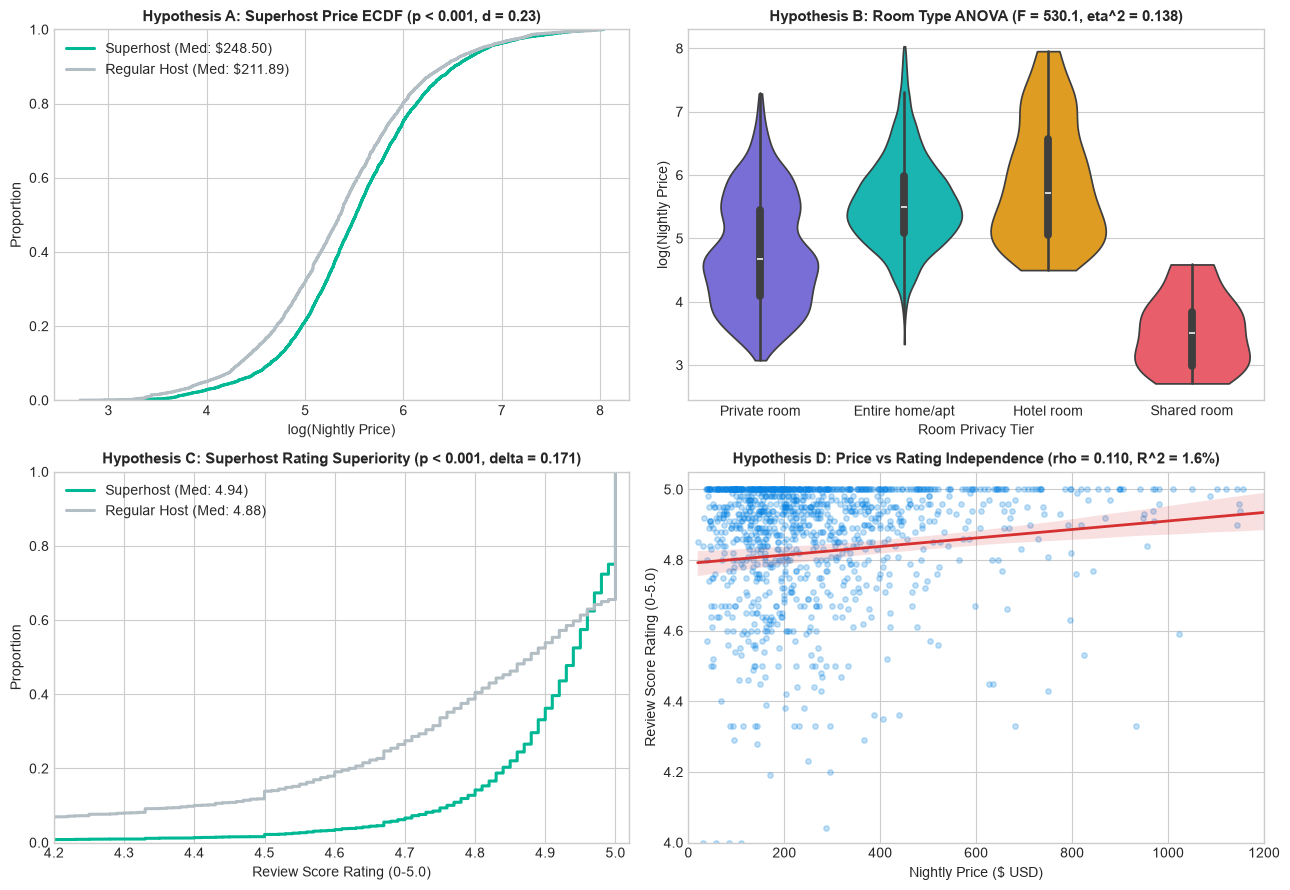

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Panel 1: Superhost Price ECDF
sh_log = df[df["host_is_superhost"] == 1]["log_price"].dropna()
reg_log = df[df["host_is_superhost"] == 0]["log_price"].dropna()
sns.ecdfplot(sh_log, ax=axes[0, 0], color="#00B894", label="Superhost (Med: $248.50)", linewidth=2.2)
sns.ecdfplot(reg_log, ax=axes[0, 0], color="#B2BEC3", label="Regular Host (Med: $211.89)", linewidth=2.2)
axes[0, 0].set_title("Hypothesis A: Superhost Price ECDF (p < 0.001, d = 0.23)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("log(Nightly Price)")
axes[0, 0].legend(loc="upper left")

# Panel 2: Room Type Log Price Violin Plot
sns.violinplot(data=df, x="room_type", y="log_price", palette=["#6C5CE7", "#00CEC9", "#FFA502", "#FF4757"], ax=axes[0, 1], cut=0)
axes[0, 1].set_title("Hypothesis B: Room Type ANOVA (F = 530.1, eta^2 = 0.138)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Room Privacy Tier")
axes[0, 1].set_ylabel("log(Nightly Price)")

# Panel 3: Superhost Ratings ECDF
df_rated = df.dropna(subset=["review_scores_rating"])
sh_r = df_rated[df_rated["host_is_superhost"] == 1]["review_scores_rating"]
reg_r = df_rated[df_rated["host_is_superhost"] == 0]["review_scores_rating"]
sns.ecdfplot(sh_r, ax=axes[1, 0], color="#00B894", label="Superhost (Med: 4.94)", linewidth=2.2)
sns.ecdfplot(reg_r, ax=axes[1, 0], color="#B2BEC3", label="Regular Host (Med: 4.88)", linewidth=2.2)
axes[1, 0].set_title("Hypothesis C: Superhost Rating Superiority (p < 0.001, delta = 0.171)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Review Score Rating (0-5.0)")
axes[1, 0].set_xlim(4.2, 5.02)
axes[1, 0].legend(loc="upper left")

# Panel 4: Price vs Rating Scatter
sns.regplot(data=df_rated.sample(n=1200, random_state=42), x="price", y="review_scores_rating",
            scatter_kws={"alpha": 0.25, "color": "#0984E3", "s": 15},
            line_kws={"color": "#D63031", "linewidth": 2}, ax=axes[1, 1])
axes[1, 1].set_title("Hypothesis D: Price vs Rating Independence (rho = 0.110, R^2 = 1.6%)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Nightly Price ($ USD)")
axes[1, 1].set_ylabel("Review Score Rating (0-5.0)")
axes[1, 1].set_xlim(0, 1200)
axes[1, 1].set_ylim(4.0, 5.05)

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/03_hypothesis_tests_summary.png", dpi=150)
plt.show()


## 6. Synthesis Table: Formal Statistical Test Results

| Hypothesis | Null Hypothesis ($H_0$) | Test Chosen | Test Statistic | p-value | Effect Size | Decision |
|---|---|---|---|---|---|---|
| **A: Superhost Price** | $\mu_{	ext{SH}} = \mu_{	ext{Reg}}$ | Welch's $t$ / Mann-Whitney $U$ | $t = 11.57, U = 1.41 	imes 10^7$ | $p < 0.001$ | Cohen's $d = 0.233$ | **Reject $H_0$** (Superhosts charge +$36.61/night more) |
| **B: Room Type Price** | $\mu_{	ext{Entire}} = \mu_{	ext{Priv}} = \dots$ | One-Way ANOVA / Kruskal-Wallis | $F = 530.07, H = 1008.79$ | $p < 0.001$ | $\eta^2 = 0.138$ | **Reject $H_0$** (Room type explains 13.8% of variance) |
| **C: Superhost Ratings**| $	ext{dist}_{	ext{SH}} = 	ext{dist}_{	ext{Reg}}$ | Mann-Whitney $U$ (1-sided) | $U = 1.05 	imes 10^7$ | $p < 0.001$ | Cliff's $\delta = 0.171$ | **Reject $H_0$** (Superhosts achieve higher ratings) |
| **D: Price vs. Rating** | $ho = 0$ (Independence) | Spearman Rank $ho$ / Pearson $r$ | $ho = 0.110, r = 0.129$ | $p < 0.001$ | $R^2 = 1.67\%$ | **Statistically Significant, Practically Trivial** (Independent) |
